# IDENTIFICACIÓN NADADORES EN PISCINA - DELIMITACIÓN DE LA PISCINA Y ELIMINACIÓN DE CARRILES (VISTA SUPERIOR)

Juan David Hurtado Molano

Laura Sofía Salamanca Barrera


## De qué se parte

En la exploración se armó una máscara de agua con el tono (H) que separaba casi todo el fondo. Afuera de esa máscara quedaban los nadadores, las corcheras, el borde de la piscina y los gráficos de la transmisión.

En esta parte se trabaja solo la vista superior (IS). Hay que trazar las líneas de los carriles con Hough, delimitar la piscina con esas líneas y sus intersecciones, y quitar el agua, las líneas guía del fondo, los gráficos y lo que está fuera de la piscina.

De cada imagen sale la imagen limpia sobre fondo negro. Las corcheras quedan marcadas y, entre ellas, lo que no es agua. Los nadadores se dejan como están. Acá no se procesan.

Tiene que servir para las 20 imágenes de muestra sin mover parámetros de una foto a otra.


In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 72

ROOT = Path.cwd()
if not (ROOT / "data" / "images").exists():
    ROOT = ROOT.parent

CARPETA = ROOT / "data" / "images" / "IS"
SALIDA = ROOT / "output" / "delimitacion" / "IS"
GUARDAR = True          # guarda el resultado en output/delimitacion/IS

# Se trabaja a la mitad de la resolución (960 x 540). Todos los tamaños en píxeles
# de los filtros y umbrales de este notebook están pensados para esa escala.
ESCALA = 0.5

def leer(ruta):
    img = cv2.imread(str(ruta))
    if img is None:
        raise FileNotFoundError(ruta)
    return cv2.resize(img, None, fx=ESCALA, fy=ESCALA, interpolation=cv2.INTER_AREA)

rutas = sorted(CARPETA.glob("*.jpg"))
imagenes = {r.stem: leer(r) for r in rutas}
print(len(imagenes), "imágenes:", ", ".join(imagenes))

def rgb(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def mostrar(lista, titulos=None, columnas=2, ancho=8, cmap='gray'):
    filas = int(np.ceil(len(lista) / columnas))
    fig, ax = plt.subplots(filas, columnas, figsize=(ancho * columnas, ancho * 0.58 * filas))
    ax = np.atleast_1d(ax).ravel()
    for i, a in enumerate(ax):
        a.axis('off')
        if i < len(lista):
            im = lista[i]
            a.imshow(rgb(im) if im.ndim == 3 else im, cmap=cmap)
            if titulos: a.set_title(titulos[i])
    plt.tight_layout(); plt.show()

# imágenes de ejemplo: una toma lejana (la mayoría) y una toma cercana en diagonal
EJ_LEJOS, EJ_CERCA = "IS_00738", "IS_01230"


20 imágenes: IS_00123, IS_00246, IS_00369, IS_00492, IS_00615, IS_00738, IS_00861, IS_00984, IS_01107, IS_01230, IS_01353, IS_01476, IS_01599, IS_01722, IS_01845, IS_01968, IS_02091, IS_02214, IS_02337, IS_02460


## Máscara de agua

Se parte de lo de la exploración: el agua se separa por tono. Hay dos cambios.

El rango de H se centra en el pico del histograma de cada imagen, y no se deja fijo en 90-110. En las 20 imágenes ese pico queda entre 97 y 98, así que el resultado es casi el mismo. Si cambia la luz o la cámara, el rango se corre solo. Va de pico - 10 a pico + 12. Hacia abajo está el verde de las corcheras de los bordes, H cerca de 84, y hacia arriba el azul de las corcheras azules, H cerca de 112.

Las líneas guía del fondo tienen el mismo tono que el agua, H cerca de 111, pero son muy oscuras. La máscara las deja casi todas como agua. Es lo que se busca, porque son ruido del fondo.

La limpieza pasa de la votación vertical 1x15 a una mediana 5x5. La ventana vertical servía en la foto de la exploración, donde los carriles estaban casi verticales. En las tomas cercanas (IS_00984, IS_01230) los carriles salen en diagonal y esa ventana les borra pedazos. Esos pedazos son los que después tiene que ver Hough. La mediana 5x5 es igual de ancha que de alta, así que no se come una dirección más que otra.


In [2]:
def mascara_agua(img, delta_bajo=10, delta_alto=12, k=5):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    hist = cv2.calcHist([hsv], [0], None, [180], [0, 180]).ravel()
    pico = int(hist.argmax())
    agua = cv2.inRange(hsv[..., 0], pico - delta_bajo, pico + delta_alto)
    agua = cv2.medianBlur(agua, k)
    return agua, hsv, pico

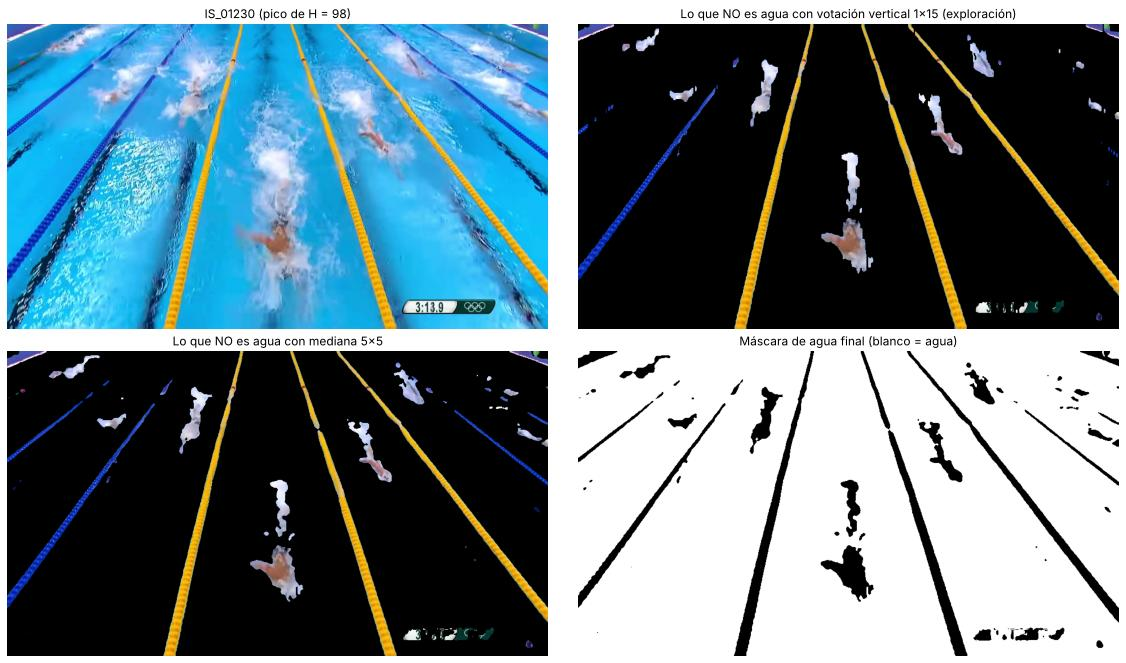

In [3]:
img = imagenes[EJ_CERCA]
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
pico = int(cv2.calcHist([hsv], [0], None, [180], [0, 180]).argmax())
crudo = cv2.inRange(hsv[..., 0], pico - 10, pico + 12)
vertical = cv2.medianBlur(((cv2.blur(crudo, (1, 15)) > 127) * 255).astype(np.uint8), 3)
agua, _, _ = mascara_agua(img)

mostrar([img,
         cv2.bitwise_and(img, img, mask=255 - vertical),
         cv2.bitwise_and(img, img, mask=255 - agua),
         agua],
        [f"{EJ_CERCA} (pico de H = {pico})",
         "Lo que NO es agua con votación vertical 1x15 (exploración)",
         "Lo que NO es agua con mediana 5x5",
         "Máscara de agua final (blanco = agua)"])

Con la ventana vertical, las corcheras azules de arriba a la derecha se cortan en pedazos y la de la izquierda pierde tramos. Con la mediana 5x5 quedan continuas. Las burbujas y la espuma alrededor de los nadadores sí quedan fuera del agua. Eso no le estorba a Hough: son manchas y no tienen una dirección que se repita.


## Canny

Si el Canny corre sobre la imagen original, el reflejo del agua y las burbujas meten miles de bordes chicos, sobre todo en los carriles con brillo. Hough los cuenta como votos y aparecen rectas que no son carriles.

Por eso el agua se aplana antes del Canny. Los píxeles de agua se reemplazan por un mismo gris, la mediana del agua. Ahí no queda gradiente, y los bordes que sobreviven son de corcheras, nadadores, muros y gráficos. Después va un gaussiano 5x5 y Canny con umbrales 50 y 150.


In [4]:
def canny_limpio(img, agua, t1=50, t2=150):
    gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    limpio = gris.copy()
    limpio[agua > 0] = int(np.median(gris[agua > 0]))
    limpio = cv2.GaussianBlur(limpio, (5, 5), 0)
    return cv2.Canny(limpio, t1, t2), limpio

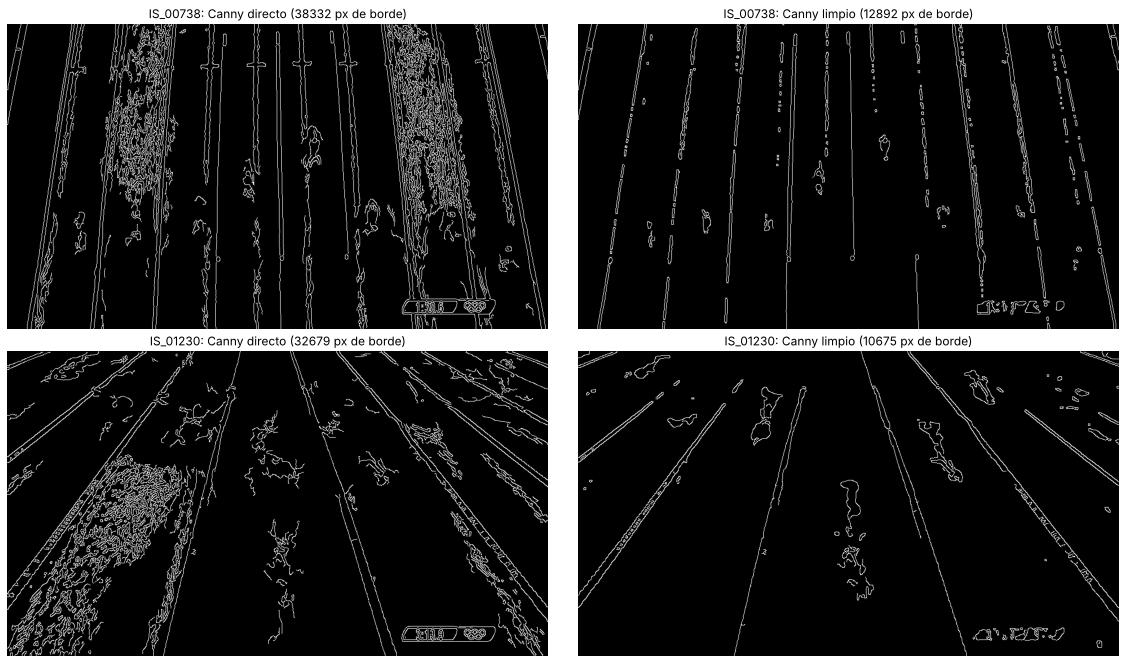

In [5]:
lista, titulos = [], []
for nombre in (EJ_LEJOS, EJ_CERCA):
    img = imagenes[nombre]
    agua, _, _ = mascara_agua(img)
    gris = cv2.GaussianBlur(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (5, 5), 0)
    crudo = cv2.Canny(gris, 50, 150)
    limpio, _ = canny_limpio(img, agua)
    lista += [crudo, limpio]
    titulos += [f"{nombre}: Canny directo ({int((crudo > 0).sum())} px de borde)",
                f"{nombre}: Canny limpio ({int((limpio > 0).sum())} px de borde)"]
mostrar(lista, titulos)

El Canny limpio deja menos de la mitad de los píxeles de borde. Lo que queda son, sobre todo, los dos bordes de cada corchera. La textura de las burbujas en los carriles con brillo casi desaparece. Esa máscara es la que entra a Hough.


## Hough

Se usa `cv2.HoughLines`, la estándar, porque devuelve la recta completa y no un segmento:

$$x\cos\theta + y\sin\theta = \rho$$

Con la recta completa se pueden calcular las intersecciones. El umbral de votos es el 12% de la altura de la imagen y se guardan como máximo 300 rectas. OpenCV las devuelve de la que tiene más votos a la que tiene menos.

Cada recta queda en coordenadas homogéneas como $l = (\cos\theta,\ \sin\theta,\ -\rho)$. Un punto $(x, y, 1)$ está en la recta si el producto escalar da 0. El cruce de dos rectas es el producto cruz.


In [6]:
def hough_rectas(bordes, frac_votos=0.12, max_rectas=300):
    R = cv2.HoughLines(bordes, 1, np.pi / 180, int(frac_votos * bordes.shape[0]))
    if R is None:
        return np.zeros((0, 2)), np.zeros((0, 3))
    R = R.reshape(-1, R.shape[-1])[:max_rectas, :2]
    rho, th = R[:, 0], R[:, 1]
    L = np.c_[np.cos(th), np.sin(th), -rho]          # recta homogenea: x cos + y sin - rho = 0
    return R, L

def segmento_en_imagen(l, w, h):
    bordes = [np.array([1, 0, 0.]), np.array([1, 0, -(w - 1)]),
              np.array([0, 1, 0.]), np.array([0, 1, -(h - 1)])]
    pts = []
    for b in bordes:
        p = np.cross(l, b)
        if abs(p[2]) < 1e-9:
            continue
        p = p[:2] / p[2]
        if -1 <= p[0] <= w and -1 <= p[1] <= h:
            pts.append(p)
    if len(pts) < 2:
        return None
    pts = np.array(pts)
    d = np.linalg.norm(pts[:, None] - pts[None], axis=2)
    i, j = np.unravel_index(d.argmax(), d.shape)
    return pts[i], pts[j]

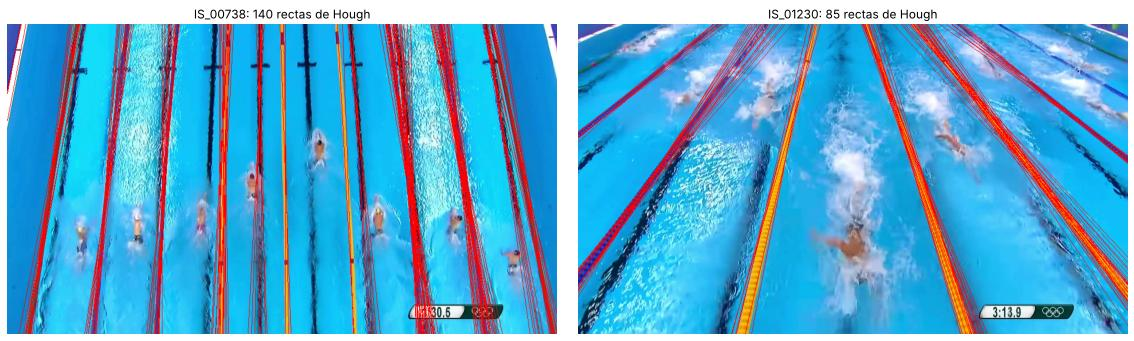

In [7]:
lista, titulos = [], []
for nombre in (EJ_LEJOS, EJ_CERCA):
    img = imagenes[nombre]
    agua, _, _ = mascara_agua(img)
    bordes, _ = canny_limpio(img, agua)
    R, L = hough_rectas(bordes)
    vis = img.copy()
    for l in L:
        s = segmento_en_imagen(l, img.shape[1], img.shape[0])
        if s: cv2.line(vis, tuple(map(int, s[0])), tuple(map(int, s[1])), (0, 0, 255), 1)
    lista.append(vis); titulos.append(f"{nombre}: {len(L)} rectas de Hough")
mostrar(lista, titulos)

Hough sí encuentra las corcheras, pero cada una sale varias veces: una recta por borde, y a veces con un ángulo un poco distinto. También salen rectas que no son carriles, de los gráficos, de los nadadores y del borde de la piscina. Hay que separar las que son carril y juntar las que son la misma corchera.


## Punto de fuga

En la piscina las corcheras son paralelas. En la foto no lo son: por la perspectiva se cortan todas en un mismo punto. En las tomas lejanas ese punto queda muy por encima de la imagen, con y entre -1500 y -3000 px más o menos. En las cercanas queda más cerca, alrededor de -150 px.

Eso es lo que le faltaba a `delimitar_carriles.ipynb`. Ahí se buscaban dos orientaciones con k-means y cuatro esquinas, como si los cuatro lados de la piscina estuvieran en el cuadro. En esta vista los extremos casi nunca se ven, y los carriles no comparten un solo ángulo: forman un haz que pasa por el punto de fuga.

Para hallarlo se toman las 80 rectas con más votos. Se cruza cada par y se cuenta cuántas de todas las rectas apuntan a ese cruce. Apunta si el ángulo entre la recta y la dirección hacia el punto es menor a 1.5°. Se queda el punto que junta más rectas.

Con esas rectas se busca el punto $v$ que minimiza $\sum (l_i \cdot v)^2$. Es el vector singular más chico de la matriz que apila las $l_i$, y se repite tres veces.

Como está en coordenadas homogéneas, el punto puede quedar muy lejos. Si las rectas son paralelas, queda en el infinito y el cálculo es el mismo.


In [8]:
def residuos_angulares(L, vp, c):
    """Angulo (grados) entre cada recta y la direccion que la une con el punto de fuga."""
    n = L[:, :2]
    d = np.c_[-n[:, 1], n[:, 0]]
    p = c[None] - (n @ c + L[:, 2])[:, None] * n      # punto de la recta mas cercano al centro
    v = vp[:2][None] - p * vp[2]
    nv = np.linalg.norm(v, axis=1) + 1e-12
    s = np.abs(d[:, 0] * v[:, 1] - d[:, 1] * v[:, 0]) / nv
    return np.degrees(np.arcsin(np.clip(s, 0, 1)))

def punto_fuga(L, shape, tol=1.5, top=80):
    h, w = shape[:2]
    c = np.array([w / 2, h / 2])
    Ls = L[:top]
    mejor = None
    for i in range(len(Ls)):
        for j in range(i + 1, len(Ls)):
            if abs(Ls[i][:2] @ Ls[j][:2]) > np.cos(np.radians(1.0)):
                continue                                   # casi la misma recta
            vp = np.cross(Ls[i], Ls[j])                    # interseccion = producto cruz
            vp /= np.linalg.norm(vp)
            n_in = (residuos_angulares(L, vp, c) < tol).sum()
            if mejor is None or n_in > mejor[0]:
                mejor = (n_in, vp)
    vp = mejor[1]
    for _ in range(3):                                     # refinamiento por minimos cuadrados
        inl = residuos_angulares(L, vp, c) < tol
        _, _, Vt = np.linalg.svd(L[inl])
        vp = Vt[-1] / np.linalg.norm(Vt[-1])
    if vp[2] < 0:
        vp = -vp
    return vp, residuos_angulares(L, vp, c) < tol

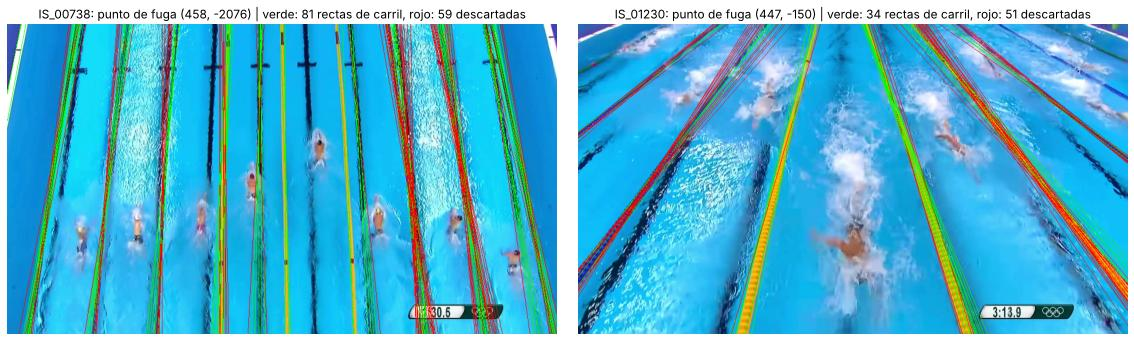

Punto de fuga en las 20 imágenes (coordenadas a escala 0.5):


  IS_00123: (    454,   -1536)   rectas de carril  85 de 138


  IS_00246: (    466,   -2035)   rectas de carril  50 de 123


  IS_00369: (    464,   -2066)   rectas de carril  53 de 88


  IS_00492: (    424,   -2016)   rectas de carril  49 de 85


...

  IS_01968: (    427,   -2065)   rectas de carril  40 de 77


  IS_02091: (    449,   -1959)   rectas de carril  64 de 116


  IS_02214: (    432,   -1996)   rectas de carril  57 de 95


  IS_02337: (    444,   -1640)   rectas de carril  56 de 79


  IS_02460: (    463,   -1490)   rectas de carril  63 de 101


In [9]:
lista, titulos = [], []
for nombre in (EJ_LEJOS, EJ_CERCA):
    img = imagenes[nombre]
    agua, _, _ = mascara_agua(img)
    bordes, _ = canny_limpio(img, agua)
    R, L = hough_rectas(bordes)
    vp, inl = punto_fuga(L, img.shape)
    vis = img.copy()
    for l, ok in zip(L, inl):
        s = segmento_en_imagen(l, img.shape[1], img.shape[0])
        if s: cv2.line(vis, tuple(map(int, s[0])), tuple(map(int, s[1])), (0, 255, 0) if ok else (0, 0, 255), 1)
    lista.append(vis)
    titulos.append(f"{nombre}: punto de fuga ({vp[0]/vp[2]:.0f}, {vp[1]/vp[2]:.0f}) | verde: {inl.sum()} rectas de carril, rojo: {(~inl).sum()} descartadas")
mostrar(lista, titulos)

print("Punto de fuga en las 20 imágenes (coordenadas a escala 0.5):")
for nombre, img in imagenes.items():
    agua, _, _ = mascara_agua(img)
    bordes, _ = canny_limpio(img, agua)
    R, L = hough_rectas(bordes)
    vp, inl = punto_fuga(L, img.shape)
    print(f"  {nombre}: ({vp[0]/vp[2]:7.0f}, {vp[1]/vp[2]:7.0f})   rectas de carril {inl.sum():3d} de {len(L)}")

Las verdes son las rectas que pasan por el punto de fuga: las corcheras y el borde de la piscina, que también corre paralelo a los carriles. Entre las rojas hay bordes de gráficos y contornos de nadadores, y también rectas que sí están sobre una corchera pero con uno o dos grados de diferencia. Hough parte $\theta$ cada 1° y el borde de la corchera no es perfectamente recto. De este Hough solo se usa el punto de fuga. Las corcheras se vuelven a buscar abajo, ya obligadas a pasar por ese punto.

En las tomas lejanas el punto cae siempre cerca de x entre 430 y 490, casi en la mitad horizontal. La cámara está centrada sobre la piscina. En las dos tomas cercanas el punto baja mucho, cerca de -150 y de -220. Ahí la perspectiva se nota más.


## Corcheras desde el punto de fuga

Si todas las corcheras pasan por el punto de fuga, para encontrarlas basta con mirar las rectas que salen de ahí. Se recorre la imagen de izquierda a derecha y, en cada recta, se cuenta qué fracción de los píxeles no es agua. Eso arma una curva, el perfil.

* Sobre una corchera casi toda la recta es no-agua. El perfil tiene un pico alto y angosto.
* Un nadador o un poco de espuma ocupan un tramo corto y dejan un bulto bajo.
* El muro y el borde de la piscina dejan una meseta cerca de 1 en los extremos.

La posición de cada recta se mide en píxeles, a la altura del centro de la imagen.

Cada tramo de la curva que pasa de 0.12 es una banda. De la banda se saca el color, con la mediana de H, S y V de los píxeles que no son agua, el valor máximo de la curva, y la cobertura: en qué fracción del largo de la recta aparece algo. Una corchera, aunque sea punteada, aparece a lo largo. Un nadador o un gráfico solo ocupan un pedazo.

Los tonos son los de la exploración. Amarilla entre H 15 y 40, verde entre 45 y 92, azul entre 105 y 135. La línea guía es un azul muy oscuro, con V menor a 110 y S mayor a 120. El blanco, espuma o muro, tiene S menor a 70 y V mayor a 150.

Se marca como corchera si el color es amarillo, verde o azul, la cobertura llega al menos a 0.55 y el pico al menos a 0.2. Se marca como muro si el pico llega a 0.9 y la banda es ancha, más de 2.2 veces el ancho de las amarillas, o si es una meseta en el extremo y no tiene color de corchera. Lo que no entra en eso queda como línea guía o como otra cosa.


In [10]:
def mapa_carril(vp, shape):
    """u: coordenada transversal a los carriles (constante sobre cada recta del haz que
    pasa por el punto de fuga). r: coordenada a lo largo del carril."""
    h, w = shape[:2]
    c = np.array([w / 2, h / 2])
    ys, xs = np.mgrid[0:h, 0:w].astype(np.float64)
    if abs(vp[2]) * 1e5 < np.linalg.norm(vp[:2]):          # punto de fuga en el infinito
        d = vp[:2] / np.linalg.norm(vp[:2]); n = np.array([-d[1], d[0]])
        U = (xs - c[0]) * n[0] + (ys - c[1]) * n[1]
        Rr = xs * d[0] + ys * d[1]
        geo = dict(finito=False, d=d, n=n, c=c)
    else:
        v = vp[:2] / vp[2]; d0 = c - v; D = np.linalg.norm(d0); d0 /= D
        vx, vy = xs - v[0], ys - v[1]
        U = np.arctan2(d0[0] * vy - d0[1] * vx, d0[0] * vx + d0[1] * vy) * D
        Rr = np.hypot(vx, vy)
        geo = dict(finito=True, v=v, d0=d0, D=D, c=c)
    geo['signo'] = 1.0 if U[h - 1, w - 1] >= U[h - 1, 0] else -1.0   # u crece de izquierda a derecha
    return U * geo['signo'], Rr, geo

def recta_de_u(u, vp, geo):
    u = u * geo['signo']
    if not geo['finito']:
        p = geo['c'] + u * geo['n']
    else:
        a = u / geo['D']
        R = np.array([[np.cos(a), -np.sin(a)], [np.sin(a), np.cos(a)]])
        p = geo['v'] + R @ geo['d0'] * geo['D']
    l = np.cross(vp, [p[0], p[1], 1.0])
    return l / np.linalg.norm(l[:2])

def perfil_transversal(U, mascara, min_px=20):
    u0 = np.floor(U.min())
    b = (U - u0).astype(int).ravel()
    tot = np.bincount(b).astype(float)
    nn = np.bincount(b, weights=mascara.ravel().astype(float), minlength=len(tot))
    fr = nn / np.maximum(tot, 1)
    fr[tot < min_px] = 0
    fr = np.convolve(fr, np.ones(3) / 3, 'same')
    return np.arange(len(tot)) + u0, fr, tot

CORCHERA = ('amarilla', 'azul', 'verde')

def clase_color(H, S, V):
    if S < 70 and V > 150: return 'blanco'
    if V < 110 and S > 120 and 95 <= H <= 130: return 'guia'
    if V < 70: return 'oscuro'
    if 15 <= H <= 40 and S > 100: return 'amarilla'
    if 45 <= H <= 92 and S > 80: return 'verde'
    if 105 <= H <= 135 and S > 100: return 'azul'
    return 'otro'

def _corridas(b):
    idx = np.flatnonzero(np.diff(np.r_[0, b.astype(int), 0]))
    return list(zip(idx[::2], idx[1::2]))

def bandas_del_perfil(U, Rr, agua, hsv, us, fr, tot, umbral=0.12, hueco=3, n_r=40):
    no_agua = agua == 0
    corr = []
    for i, j in _corridas(fr > umbral):
        if corr and i - corr[-1][1] <= hueco: corr[-1] = (corr[-1][0], j)
        else: corr.append((i, j))
    validos = np.flatnonzero(tot >= 20); primero, ultimo = validos[0], validos[-1]
    rmin, rmax = Rr.min(), Rr.max()
    bandas = []
    for i, j in corr:
        a, b = us[i], us[j - 1] + 1
        dentro = (U >= a) & (U < b)
        sel = dentro & no_agua
        if sel.sum() < 10:
            continue
        H, S, V = np.median(hsv[sel], axis=0)
        rb_tot = np.unique(((Rr[dentro] - rmin) / (rmax - rmin + 1e-9) * n_r).astype(int))
        rb_si = np.unique(((Rr[sel] - rmin) / (rmax - rmin + 1e-9) * n_r).astype(int))
        bandas.append(dict(u0=float(a), u1=float(b), ancho=float(b - a), pico=float(fr[i:j].max()),
                           cobertura=len(rb_si) / max(len(rb_tot), 1),
                           extremo=bool(i <= primero + 1 or j - 1 >= ultimo - 1),
                           H=float(H), S=float(S), V=float(V), clase=clase_color(H, S, V)))
    return bandas

def clasificar_bandas(bandas, cob_min=0.55, pico_min=0.2):
    cor = [b for b in bandas if b['clase'] in CORCHERA and b['cobertura'] >= cob_min and b['pico'] >= pico_min]
    ref = [b['ancho'] for b in cor if b['clase'] == 'amarilla'] or [b['ancho'] for b in cor] or [10]
    w_ref = float(np.median(ref))
    for b in bandas:
        es_muro = b['pico'] >= 0.9 and (b['ancho'] >= 2.2 * w_ref or (b['extremo'] and b['clase'] not in CORCHERA))
        b['tipo'] = 'muro' if es_muro else 'corchera' if b in cor else 'guia' if b['clase'] == 'guia' else 'otro'
    return w_ref

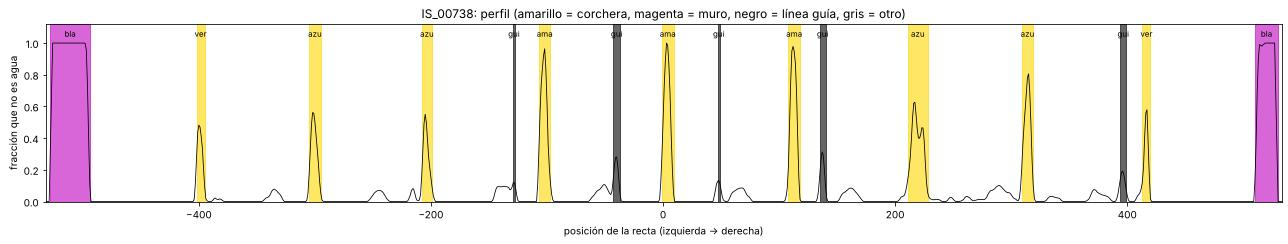

 inicio     fin  ancho  pico   cob   H    S    V   clase      tipo
   -528    -494     34  1.00  1.00  115   56  213   blanco     muro
   -402    -395      7  0.48  0.97   83  229  107   verde      corchera
   -305    -295     10  0.56  0.95  113  207  185   azul       corchera
   -208    -199      9  0.55  0.95  112  232  179   azul       corchera
   -129    -128      1  0.12  0.27  112  242   60   guia       guia
   -107     -97     10  0.96  1.00   23  190  225   amarilla   corchera
    -43     -37      6  0.28  0.49  112  246   60   guia       guia
     -1       9     10  1.00  1.00   23  194  222   amarilla   corchera
     47      49      2  0.13  0.24  112  246   60   guia       guia
    108     118     10  0.98  1.00   22  189  223   amarilla   corchera
    135     140      5  0.31  0.61  112  246   74   guia       guia
    211     228     17  0.63  0.95  112  219  179   azul       corchera
    309     319     10  0.81  0.97  113  209  174   azul       corchera
    394     399  

In [11]:
img = imagenes[EJ_LEJOS]
agua, hsv, _ = mascara_agua(img)
bordes, _ = canny_limpio(img, agua)
R, L = hough_rectas(bordes)
vp, inl = punto_fuga(L, img.shape)
U, Rr, geo = mapa_carril(vp, img.shape)
us, fr, tot = perfil_transversal(U, agua == 0)
bandas = bandas_del_perfil(U, Rr, agua, hsv, us, fr, tot)
w_ref = clasificar_bandas(bandas)

COLOR_TIPO = {'corchera': 'gold', 'muro': 'm', 'guia': 'k', 'otro': '0.6'}
fig, ax = plt.subplots(figsize=(18, 3.5))
ax.plot(us, fr, 'k', lw=.8)
for b in bandas:
    ax.axvspan(b['u0'], b['u1'], color=COLOR_TIPO[b['tipo']], alpha=.6)
    ax.text((b['u0'] + b['u1']) / 2, 1.04, b['clase'][:3], ha='center', fontsize=8)
ax.set_ylim(0, 1.12); ax.set_xlim(us[0], us[-1])
ax.set_xlabel("posición de la recta (izquierda → derecha)"); ax.set_ylabel("fracción que no es agua")
ax.set_title(f"{EJ_LEJOS}: perfil (amarillo = corchera, magenta = muro, negro = línea guía, gris = otro)")
plt.tight_layout(); plt.show()

print(f"{'inicio':>7} {'fin':>7} {'ancho':>6} {'pico':>5} {'cob':>5}   H    S    V   clase      tipo")
for b in bandas:
    print(f"{b['u0']:7.0f} {b['u1']:7.0f} {b['ancho']:6.0f} {b['pico']:5.2f} {b['cobertura']:5.2f} {b['H']:4.0f} {b['S']:4.0f} {b['V']:4.0f}   {b['clase']:<10} {b['tipo']}")

En esta imagen salen nueve picos, casi a la misma distancia. Son las nueve corcheras, en el orden de la piscina de Río: verde, azul, azul, amarilla, amarilla, amarilla, azul, azul, verde. Los picos bajos que quedan entre corcheras son los tramos oscuros de las líneas guía. Las mesetas de las puntas son los muros.


## Carriles a la misma distancia

A veces una corchera no pasa lo de arriba. La verde de los bordes es oscura y delgada, y se puede pegar a una línea guía. Otras veces entra una banda que no es corchera. Para corregirlo se usa que en la piscina las corcheras están a la misma distancia.

Si esas rectas se cortan con una transversal, la posición $t_k$ de la corchera $k$ no queda pareja en la foto, por la perspectiva. Sí cumple una homografía de una sola dimensión:

$$t_k = \frac{a\,k + b}{c\,k + 1}$$

Cuando la toma es desde arriba, $c$ queda cerca de 0 y la separación se ve casi constante. En las tomas cercanas $c$ crece. La transversal es una recta que pasa por el centro de la imagen.

El ajuste es con RANSAC. Se eligen tres candidatas, se prueba cuántos carriles hay entre ellas (1, 2 o 3) y con eso se arma la homografía. Se cuentan las candidatas que caen en esa rejilla, y cada hueco vacío resta, para no quedarse con una rejilla más fina de la cuenta.

Con la que mejor cierra, se descartan las candidatas que no caen en la rejilla. Si una posición queda vacía pero el perfil tiene algo cerca, se rellena y esa corchera queda inferida. La verde es la última de cada lado, y el ajuste no pone nada más afuera.


In [12]:
def u_a_t(u, geo):
    """Coordenada proyectiva: corte del haz con la recta transversal que pasa por el centro."""
    return geo['D'] * np.tan(np.asarray(u, float) / geo['D']) if geo['finito'] else np.asarray(u, float)

def t_a_u(t, geo):
    return geo['D'] * np.arctan(np.asarray(t, float) / geo['D']) if geo['finito'] else np.asarray(t, float)

def homografia_1d(k, t):
    """t = (a k + b)/(c k + 1)  ->  a k + b - c k t = t (sistema lineal)."""
    k = np.asarray(k, float); t = np.asarray(t, float)
    A = np.c_[k, np.ones_like(k), -k * t]
    a, b, c = np.linalg.lstsq(A, t, rcond=None)[0]
    return lambda kq: (a * np.asarray(kq, float) + b) / (c * np.asarray(kq, float) + 1)

def _evaluar_rejilla(f, t, peso, tol, kmax=40):
    ks = np.arange(-kmax, kmax + 1)
    with np.errstate(all='ignore'):
        tk = f(ks)
    if not np.all(np.isfinite(tk)) or np.any(np.diff(tk) == 0):
        return None
    paso = np.abs(np.gradient(tk))
    idx = np.abs(tk[None] - t[:, None]).argmin(axis=1)
    res = np.abs(tk[idx] - t) / np.maximum(paso[idx], 1e-6)
    inl = res < tol
    k = ks[idx]
    for kk in np.unique(k[inl]):                      # una sola corchera por posicion
        m = np.flatnonzero(inl & (k == kk))
        if len(m) > 1:
            inl[m] = False; inl[m[np.argmin(res[m])]] = True
    if inl.sum() < 2:
        return None
    kin = k[inl]
    vacios = (kin.max() - kin.min() + 1) - len(kin)
    return peso[inl].sum() - 0.5 * vacios, k, inl

def ajustar_rejilla(t, peso, tol=0.2, gmax=3):
    t = np.asarray(t, float); peso = np.asarray(peso, float); n = len(t)
    if n < 3:
        k = np.arange(n); return k, np.ones(n, bool), homografia_1d(k, t) if n == 2 else None
    mejor = None
    for i in range(n):
        for j in range(i + 1, n):
            for l in range(j + 1, n):
                for g1 in range(1, gmax + 1):
                    for g2 in range(1, gmax + 1):
                        f = homografia_1d([0, g1, g1 + g2], [t[i], t[j], t[l]])
                        r = _evaluar_rejilla(f, t, peso, tol)
                        if r is not None and (mejor is None or r[0] > mejor[0] + 1e-9):
                            mejor = r
    _, k, inl = mejor
    f = homografia_1d(k[inl], t[inl])
    r = _evaluar_rejilla(f, t, peso, tol)
    if r is not None and r[2].sum() >= inl.sum():
        _, k, inl = r; f = homografia_1d(k[inl], t[inl])
    k0 = k[inl].min()
    return k - k0, inl, (lambda kq: f(np.asarray(kq) + k0))

def corcheras_con_rejilla(bandas, U, geo, hsv, agua, us, fr, ev_min=0.08):
    cor = [b for b in bandas if b['tipo'] == 'corchera']
    muros = [b for b in bandas if b['tipo'] == 'muro']
    if len(cor) < 2:
        for b in cor: b.update(k=0, origen='detectada')
        return cor, None
    uc = np.array([(b['u0'] + b['u1']) / 2 for b in cor])
    k, inl, f = ajustar_rejilla(u_a_t(uc, geo), [b['pico'] for b in cor])
    for b, kk, ok in zip(cor, k, inl):
        b.update(k=int(kk), origen='detectada')
        if not ok: b['tipo'] = 'descartada'
    cor = [b for b in cor if b['tipo'] == 'corchera']
    ks = [b['k'] for b in cor]; kmin, kmax = min(ks), max(ks)
    no_agua = agua == 0
    extremos = {kmin - 1: cor[np.argmin(ks)]['clase'], kmax + 1: cor[np.argmax(ks)]['clase']}
    for kq in range(kmin - 1, kmax + 2):
        if kq in ks: continue
        if extremos.get(kq) == 'verde': continue        # la corchera verde es la ultima del lado
        u = float(t_a_u(f(kq), geo))
        paso = abs(float(t_a_u(f(kq + 1), geo)) - u)
        vecinas = sorted(cor, key=lambda b: abs(b['k'] - kq))[:2]
        w = float(np.mean([b['ancho'] for b in vecinas]))
        cerca = np.abs(us - u) <= max(w, 0.15 * paso)       # ventana de busqueda
        ev = fr[cerca].max() if cerca.any() else 0
        if ev < (0.04 if kmin < kq < kmax else ev_min): continue
        if ev > 0: u = float(us[cerca][np.argmax(fr[cerca])])   # se ajusta al pico del perfil
        a, b_ = u - w / 2, u + w / 2
        if a <= U.min() + w or b_ >= U.max() - w: continue
        if any(a < m['u1'] and b_ > m['u0'] for m in muros): continue
        sel = (U >= a) & (U < b_) & no_agua
        clase = clase_color(*np.median(hsv[sel], axis=0)) if sel.sum() > 10 else '?'
        cor.append(dict(u0=a, u1=b_, ancho=w, pico=float(ev), k=kq, origen='inferida', tipo='corchera', clase=clase))
    cor = sorted(cor, key=lambda b: b['k'])
    # la corchera verde marca el final de la zona de competencia: lo que este mas afuera se descarta
    for lado in (0, 1):
        idx = [i for i, b in enumerate(cor) if b['clase'] == 'verde']
        idx = [i for i in idx if (i <= 2 if lado == 0 else i >= len(cor) - 3)]
        if not idx: continue
        if lado == 0: cor = cor[min(idx):]
        else: cor = cor[:max(idx) + 1]
    return cor, f

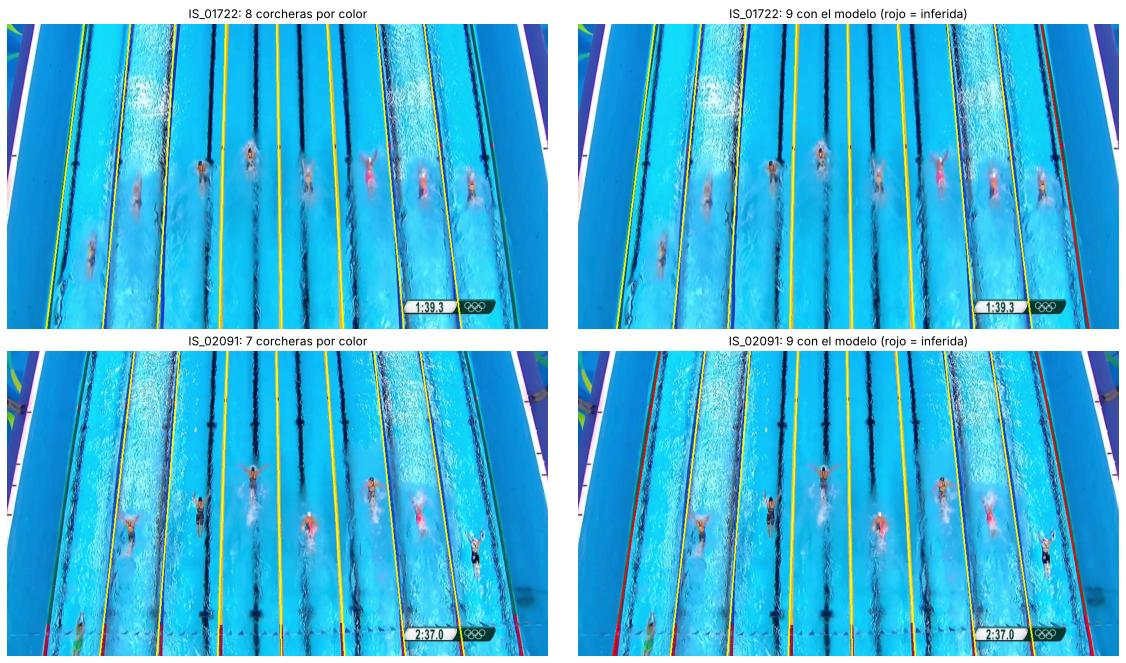

In [13]:
def corcheras_de(nombre):
    img = imagenes[nombre]
    agua, hsv, _ = mascara_agua(img)
    bordes, _ = canny_limpio(img, agua)
    R, L = hough_rectas(bordes)
    vp, inl = punto_fuga(L, img.shape)
    U, Rr, geo = mapa_carril(vp, img.shape)
    us, fr, tot = perfil_transversal(U, agua == 0)
    bandas = bandas_del_perfil(U, Rr, agua, hsv, us, fr, tot)
    clasificar_bandas(bandas)
    antes = [dict(b) for b in bandas if b['tipo'] == 'corchera']
    cor, f = corcheras_con_rejilla(bandas, U, geo, hsv, agua, us, fr)
    return img, vp, geo, antes, cor

lista, titulos = [], []
for nombre in ("IS_01722", "IS_02091"):
    img, vp, geo, antes, cor = corcheras_de(nombre)
    a, d = img.copy(), img.copy()
    h, w = img.shape[:2]
    for b in antes:
        s = segmento_en_imagen(recta_de_u((b['u0'] + b['u1']) / 2, vp, geo), w, h)
        cv2.line(a, tuple(map(int, s[0])), tuple(map(int, s[1])), (0, 255, 255), 2)
    for b in cor:
        s = segmento_en_imagen(recta_de_u((b['u0'] + b['u1']) / 2, vp, geo), w, h)
        cv2.line(d, tuple(map(int, s[0])), tuple(map(int, s[1])), (0, 255, 255) if b['origen'] == 'detectada' else (0, 0, 255), 2)
    lista += [a, d]
    titulos += [f"{nombre}: {len(antes)} corcheras por color",
                f"{nombre}: {len(cor)} con el modelo (rojo = inferida)"]
mostrar(lista, titulos)

En las dos imágenes faltaba por lo menos una corchera verde de los bordes. El modelo dice en qué posición debería estar, y si cerca hay un pico chico en el perfil, la agrega. Así, en las 18 tomas lejanas quedan las nueve corcheras.


## La piscina

Con las corcheras y los muros se arman dos zonas. Las dos están entre rectas que pasan por el punto de fuga.

La piscina va de muro a muro, por la cara interna de la meseta de cada extremo. Si de un lado no se ve el muro, ese lado lo cierra el borde de la foto.

La zona de competencia, los carriles 1 a 8, va entre las corcheras verdes de afuera. En la toma cercana a veces no se alcanza a ver el borde y la corchera exterior no es verde. Ese lado se cierra con el límite de la piscina.

Para el polígono se parte del rectángulo de la imagen y se va recortando con el semiplano de cada recta, con Sutherland-Hodgman. Cuando un lado del polígono cruza la recta, el vértice nuevo es la intersección, otra vez el producto cruz. Queda un trapecio: las dos rectas límite y los bordes de arriba y de abajo del cuadro. Si el punto de fuga cayera dentro de la foto, el polígono se cerraría en ese punto.


In [14]:
def limites(cor, muros, umin, umax):
    if not cor:
        return (umin, umax), (umin, umax)
    cmin, cmax = cor[0]['u0'], cor[-1]['u1']
    izq = [m['u1'] for m in muros if m['u1'] <= cmin + 1]
    der = [m['u0'] for m in muros if m['u0'] >= cmax - 1]
    piscina = (max(izq) if izq else umin, min(der) if der else umax)
    zona = (cor[0]['u0'] if cor[0]['clase'] == 'verde' else piscina[0],
            cor[-1]['u1'] if cor[-1]['clase'] == 'verde' else piscina[1])
    return piscina, zona

def recortar_poligono(poly, l):
    """Sutherland-Hodgman con un semiplano l.p >= 0. Los vertices nuevos son intersecciones
    (producto cruz) entre el lado del poligono y la recta."""
    out = []
    for i in range(len(poly)):
        P = np.r_[poly[i], 1.0]; Q = np.r_[poly[(i + 1) % len(poly)], 1.0]
        dp, dq = l @ P, l @ Q
        if dp >= 0: out.append(P[:2])
        if dp * dq < 0:
            X = np.cross(np.cross(P, Q), l); out.append(X[:2] / X[2])
    return np.array(out)

def poligono_entre(u_izq, u_der, vp, geo, U):
    h, w = U.shape
    poly = np.array([[0, 0], [w - 1, 0], [w - 1, h - 1], [0, h - 1]], float)
    for u, lado in ((u_izq, 1), (u_der, -1)):
        if u <= U.min() + 1 or u >= U.max() - 1:
            continue                                   # ese lado lo cierra el borde del cuadro
        l = recta_de_u(u, vp, geo)
        ys, xs = np.nonzero((U - u) * lado > 3)
        p = np.array([xs[len(xs) // 2], ys[len(ys) // 2], 1.0])
        if l @ p < 0: l = -l
        poly = recortar_poligono(poly, l)
    return poly

## Ruido

Ya con las corcheras, se arma la imagen limpia a partir de todo lo que no es agua, y se quita:

* Lo de fuera de la piscina: muros, bordes, tribuna. Se deja solo lo que está entre las dos rectas límite.
* Los restos de línea guía que no entraron como agua. Son azul muy oscuro y saturado, H de 95 a 130, S mayor a 150 y V menor a 120.
* Los gráficos de la transmisión, el reloj, el marcador y el "50M". Son rectángulos acostados, blancos, verde oscuro o negros. Una apertura de 41x13 deja pasar solo regiones sólidas y anchas, y además tienen que ser por lo menos dos veces más anchas que altas.
* Los puntos sueltos de menos de 15 px.

Corcheras y lo que hay dentro de los carriles se dejan como están.

Para verlo más claro, cada corchera se dibuja también como una recta delgada de su color, sobre negro, y encima van los píxeles de la imagen limpia. Si la corchera la puso el modelo y no el perfil, va en rojo.

La función devuelve además `solo_corcheras`, que es lo que cae en la banda de una corchera sin la espuma blanca. Sirve si después hay que separar las corcheras de lo demás.


In [15]:
def mascara_graficos(img):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV); H, S, V = cv2.split(hsv)
    m = (((S < 40) & (V > 200)) | ((H >= 50) & (H <= 95) & (V < 120) & (S > 80)) | (V < 60)).astype(np.uint8) * 255
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (15, 7)))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_RECT, (41, 13)))
    n, lab, st, _ = cv2.connectedComponentsWithStats(m)
    out = np.zeros(m.shape, np.uint8); cajas = []
    for i in range(1, n):
        x, y, w, h, a = st[i]
        if w >= 60 and w >= 2 * h and a >= 0.55 * w * h:
            cv2.rectangle(out, (int(x) - 3, int(y) - 3), (int(x + w) + 3, int(y + h) + 3), 255, -1)
            cajas.append((int(x), int(y), int(w), int(h)))
    return out, cajas

def limpiar_ruido(r, img, margen=0.35, a_min=15):
    """Ajuste de ruido. 'limpia': lo que no es agua dentro de la piscina, sin restos de lineas
    guia ni graficos de la transmision (los nadadores no se procesan, solo se dejan).
    'solo_corcheras': de lo anterior, solo lo que cae en la banda de una corchera."""
    U, hsv = r['U'], r['hsv']
    H, S, V = cv2.split(hsv)
    m_cor = np.zeros(U.shape, bool)
    for b in r['corcheras']:
        mg = max(2.0, margen * b['ancho'])
        m_cor |= (U >= b['u0'] - mg) & (U < b['u1'] + mg)
    m_guia = (S > 150) & (V < 120) & (H >= 95) & (H <= 130)
    m_piscina = (U > r['piscina'][0] + 4) & (U < r['piscina'][1] - 4)
    graf, cajas = mascara_graficos(img)
    no_agua = r['agua'] == 0
    m_blanco = (S < 70) & (V > 150)                                # espuma y bordes blancos
    corch = (no_agua & m_cor & m_piscina & ~m_guia & ~m_blanco & (graf == 0)).astype(np.uint8) * 255
    # imagen limpia: todo lo que no es agua dentro de la piscina, sin lineas guia ni graficos
    limpia = (no_agua & m_piscina & ~m_guia & (graf == 0)).astype(np.uint8) * 255
    for m in (corch, limpia):                                     # puntos sueltos
        n, lab, st, _ = cv2.connectedComponentsWithStats(m)
        m[np.isin(lab, np.flatnonzero(st[:, 4] < a_min))] = 0
    return dict(m_corcheras=m_cor, m_guias=m_guia, m_graficos=graf, cajas_graficos=cajas,
                no_agua=no_agua.astype(np.uint8) * 255, solo_corcheras=corch, limpia=limpia)

def imagen_corcheras(img, r):
    """Fondo negro con la recta de cada corchera (en su color; roja si es inferida)
    y encima los pixeles reales de la imagen limpia (corcheras y lo que hay en los carriles)."""
    colores = {'amarilla': (0, 200, 255), 'azul': (255, 80, 0), 'verde': (0, 160, 0)}
    out = np.zeros_like(img)
    h, w = img.shape[:2]
    for b in r['corcheras']:
        s = segmento_en_imagen(recta_de_u((b['u0'] + b['u1']) / 2, r['vp'], r['geo']), w, h)
        if not s: continue
        c = (0, 0, 255) if b['origen'] == 'inferida' else colores.get(b['clase'], (200, 200, 200))
        cv2.line(out, tuple(map(int, s[0])), tuple(map(int, s[1])), c, 1 if b['origen'] == 'detectada' else 2)
    m = r['limpia'] > 0
    out[m] = img[m]
    return out

### Todo en una función

`procesar_vista_superior` recibe la imagen BGR y devuelve el punto de fuga, las corcheras, el polígono de la piscina, el de la zona de competencia y la máscara de las corcheras.


In [16]:
def procesar_vista_superior(img):
    r = {}
    r['agua'], r['hsv'], r['pico_h'] = mascara_agua(img)
    r['canny'], r['gris_limpio'] = canny_limpio(img, r['agua'])
    r['hough'], L = hough_rectas(r['canny'])
    r['L'] = L
    r['vp'], r['inliers'] = punto_fuga(L, img.shape)
    r['U'], r['Rr'], r['geo'] = mapa_carril(r['vp'], img.shape)
    r['us'], r['perfil'], tot = perfil_transversal(r['U'], r['agua'] == 0)
    r['bandas'] = bandas_del_perfil(r['U'], r['Rr'], r['agua'], r['hsv'], r['us'], r['perfil'], tot)
    r['w_ref'] = clasificar_bandas(r['bandas'])
    r['corcheras'], r['rejilla'] = corcheras_con_rejilla(r['bandas'], r['U'], r['geo'], r['hsv'], r['agua'], r['us'], r['perfil'])
    r['muros'] = [b for b in r['bandas'] if b['tipo'] == 'muro']
    r['piscina'], r['zona'] = limites(r['corcheras'], r['muros'], r['U'].min(), r['U'].max())
    r['poly_piscina'] = poligono_entre(*r['piscina'], r['vp'], r['geo'], r['U'])
    r['poly_zona'] = poligono_entre(*r['zona'], r['vp'], r['geo'], r['U'])
    r.update(limpiar_ruido(r, img))
    return r

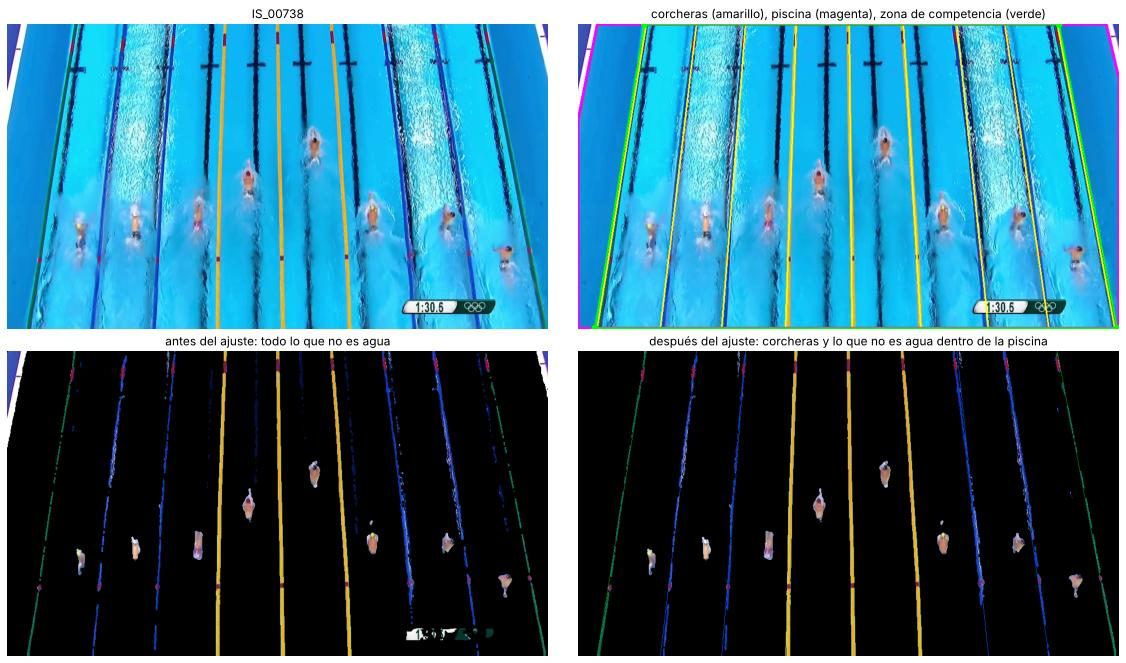

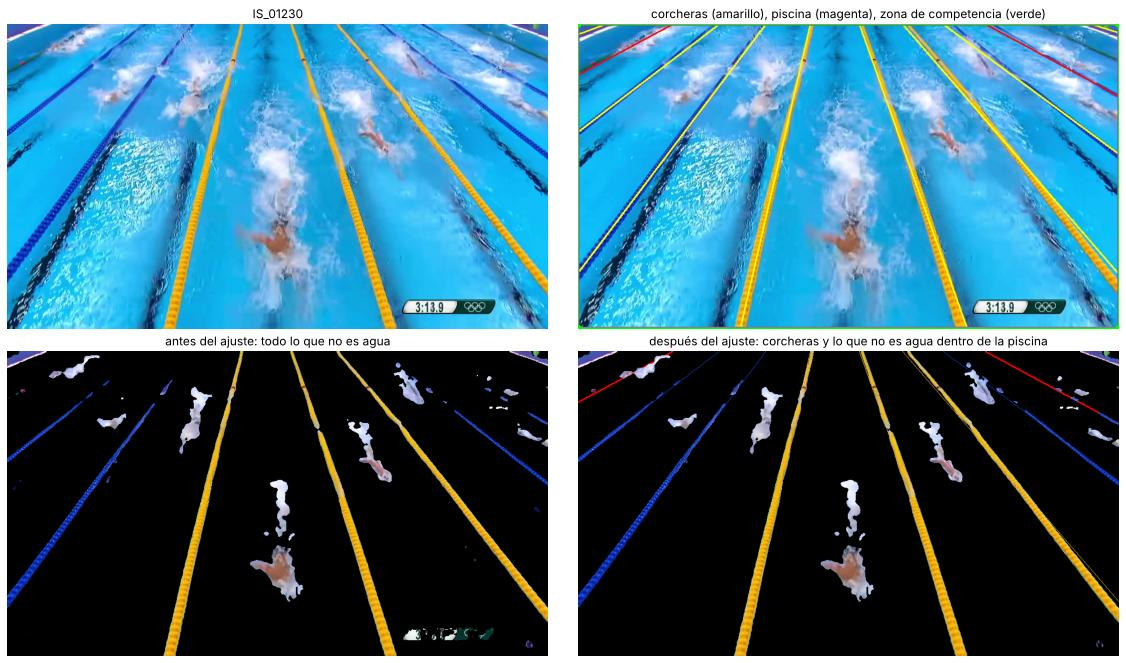

Esquinas de la zona de competencia en IS_00738 (intersecciones de las corcheras verdes con el borde del cuadro):
[[118.8  -0. ]
 [853.8   0. ]
 [956.5 539. ]
 [ 30.7 539. ]]


In [17]:
def dibujar(img, r):
    vis = img.copy(); h, w = img.shape[:2]
    for b in r['corcheras']:
        s = segmento_en_imagen(recta_de_u((b['u0'] + b['u1']) / 2, r['vp'], r['geo']), w, h)
        if s: cv2.line(vis, tuple(map(int, s[0])), tuple(map(int, s[1])),
                       (0, 255, 255) if b['origen'] == 'detectada' else (0, 0, 255), 2)
    cv2.polylines(vis, [r['poly_piscina'].astype(np.int32)], True, (255, 0, 255), 3)
    cv2.polylines(vis, [r['poly_zona'].astype(np.int32)], True, (0, 255, 0), 2)
    for p in r['poly_zona']:
        cv2.circle(vis, tuple(map(int, p)), 6, (0, 255, 0), -1)
    return vis

for nombre in (EJ_LEJOS, EJ_CERCA):
    img = imagenes[nombre]
    r = procesar_vista_superior(img)
    mostrar([img, dibujar(img, r), cv2.bitwise_and(img, img, mask=r['no_agua']), imagen_corcheras(img, r)],
            [nombre,
             "corcheras (amarillo), piscina (magenta), zona de competencia (verde)",
             "antes del ajuste: todo lo que no es agua",
             "después del ajuste: corcheras y lo que no es agua dentro de la piscina"])
r = procesar_vista_superior(imagenes[EJ_LEJOS])
print("Esquinas de la zona de competencia en", EJ_LEJOS, "(intersecciones de las corcheras verdes con el borde del cuadro):")
print(np.round(r['poly_zona'], 1))

## Las 20 imágenes

Se corre la función en todas las de IS, con los mismos parámetros. De cada una se muestra el resultado: las corcheras y lo que no es agua dentro de la piscina, ya sin el agua de fondo. En rojo está la corchera que agregó el modelo.


In [18]:
import time
resultados, filas, finales = {}, [], []
for nombre, img in imagenes.items():
    t0 = time.time()
    r = procesar_vista_superior(img)
    dt = time.time() - t0
    resultados[nombre] = r
    det = sum(b['origen'] == 'detectada' for b in r['corcheras'])
    inf = sum(b['origen'] == 'inferida' for b in r['corcheras'])
    colores = ' '.join(b['clase'][:2] for b in r['corcheras'])
    filas.append((nombre, det, inf, len(r['muros']), colores, dt))
    finales.append(imagen_corcheras(img, r))

print(f"{'imagen':<10} {'detect.':>7} {'infer.':>6} {'muros':>5}  colores (izq. a der.)          t (s)")
for n, d, i, m, c, t in filas:
    print(f"{n:<10} {d:>7} {i:>6} {m:>5}  {c:<30} {t:.2f}")

imagen     detect. infer. muros  colores (izq. a der.)          t (s)
IS_00123         9      0     2  ve az az am am am az az ve     0.92
IS_00246         9      0     2  ve az az am am am az az ve     0.72
IS_00369         9      0     2  ve az az am am am az az ve     0.74
IS_00492         9      0     0  ve az az am am am az az ve     0.78
IS_00615         9      0     2  ve az az am am am az az ve     0.87
IS_00738         9      0     2  ve az az am am am az az ve     0.83
IS_00861         8      1     4  ve az az am am am az az ve     0.72
IS_00984         8      1     0  ve az az am am am az az ot     0.76
IS_01107         9      0     3  ve az az am am am az az ve     0.75
IS_01230         8      2     0  az bl az az am am am az az az  0.66
IS_01353         9      0     2  ve az az am am am az az ve     0.75
IS_01476         9      0     2  ve az az am am am az az ve     0.66
IS_01599         9      0     2  ve az az am am am az az ve     0.77
IS_01722         8      1     2  

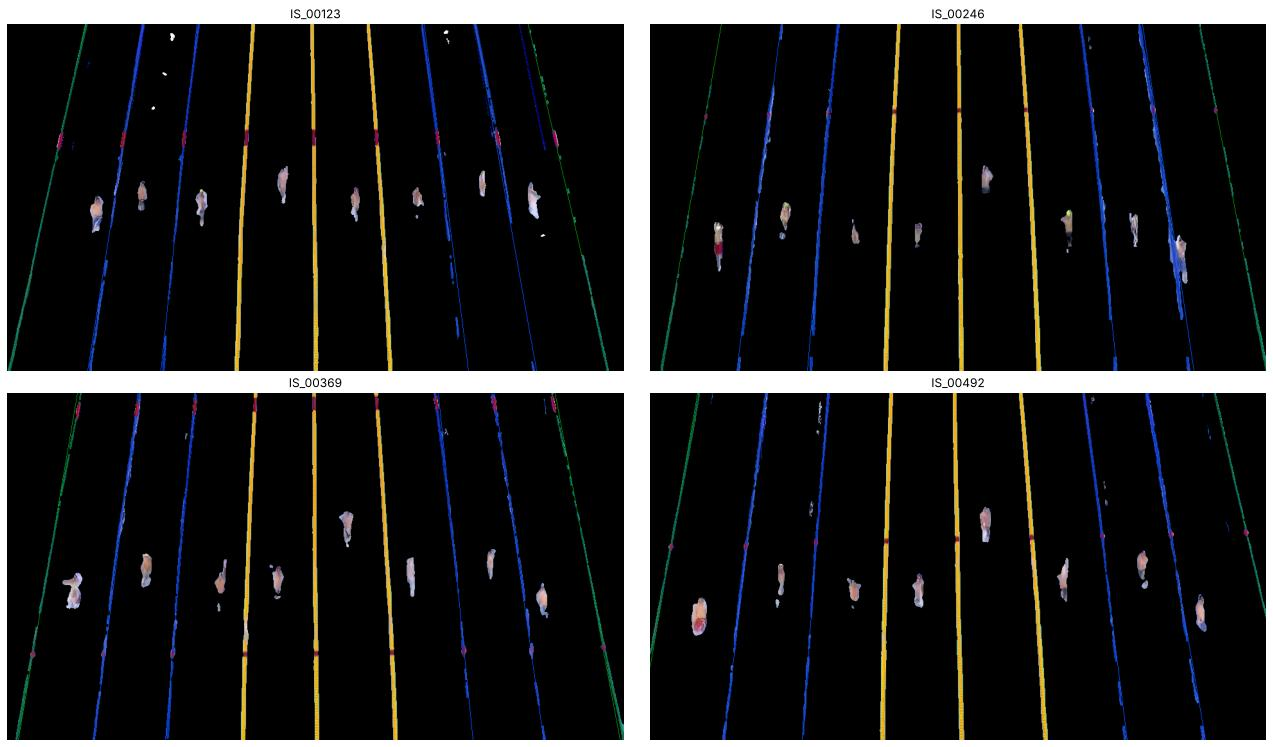

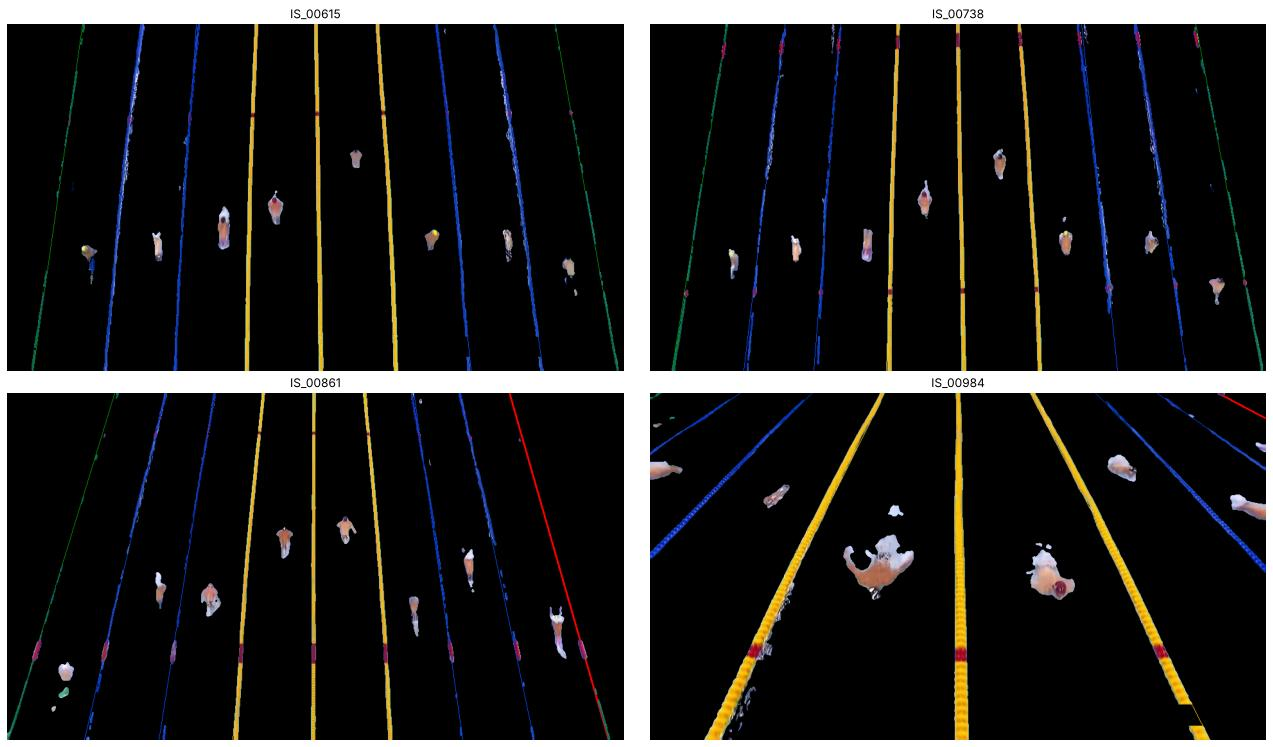

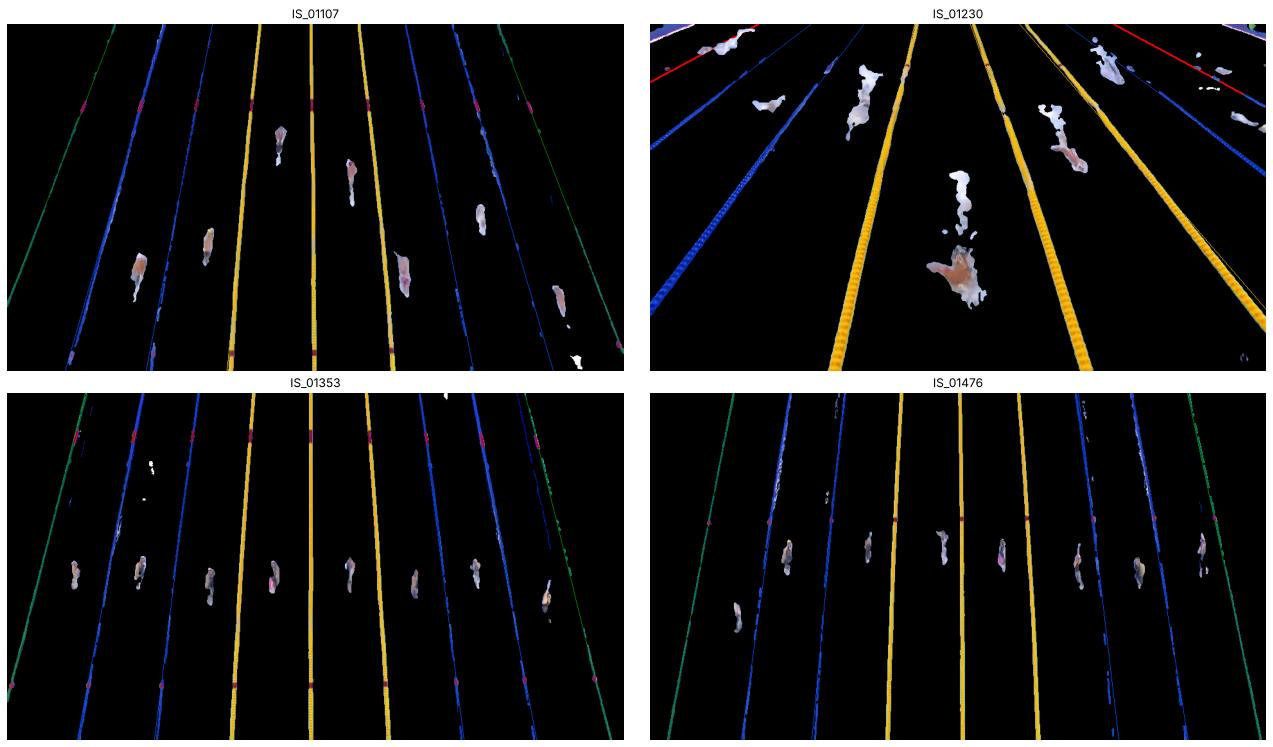

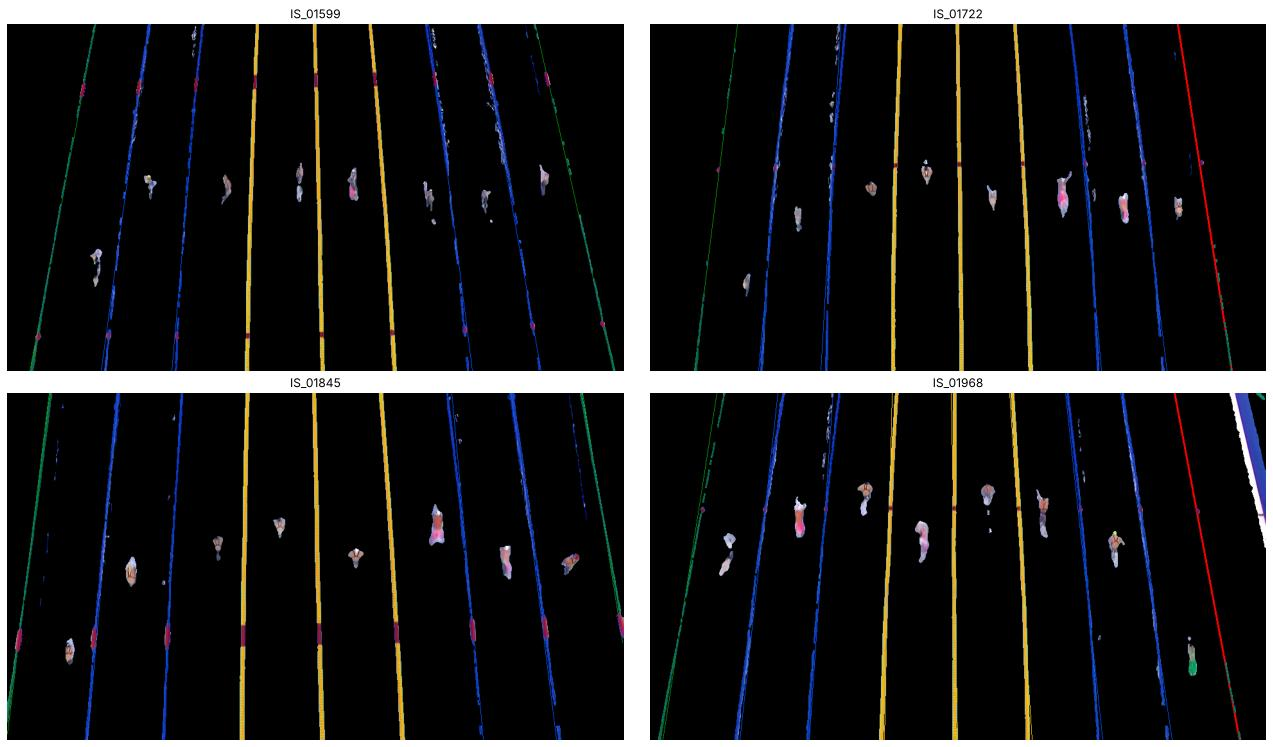

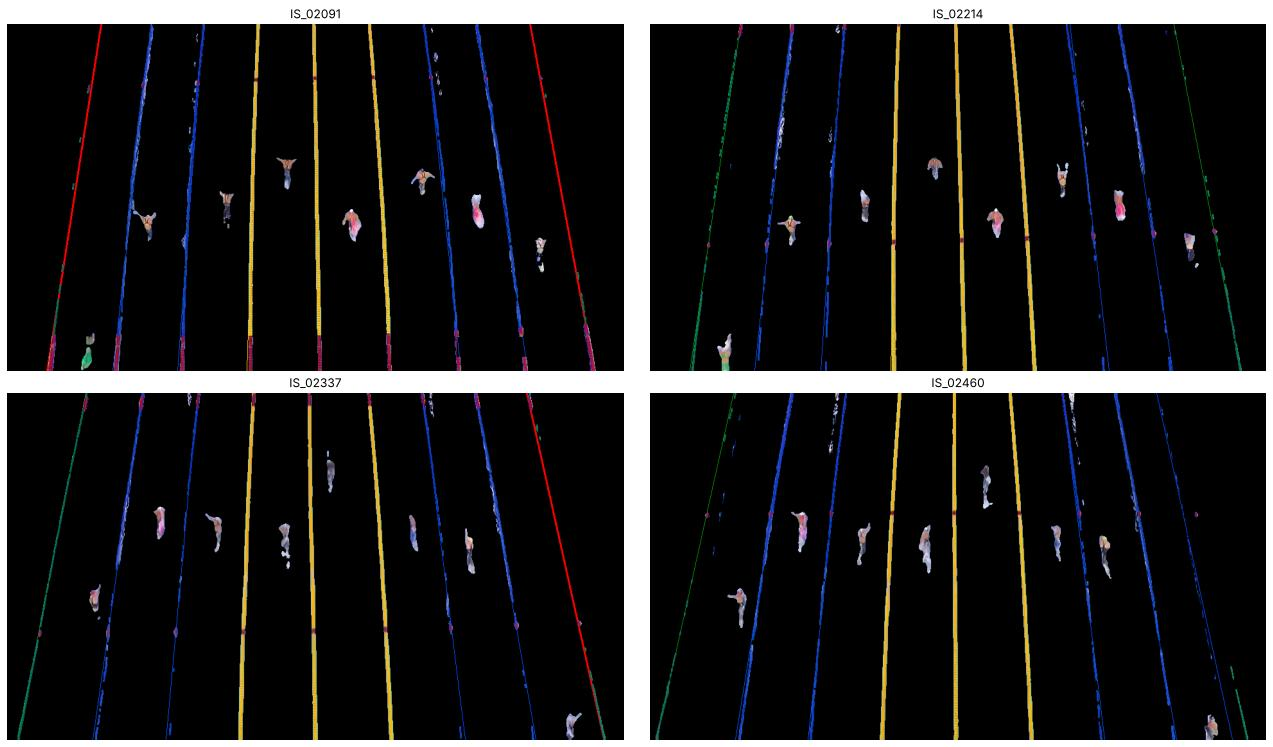

In [19]:
for i in range(0, len(finales), 4):
    mostrar(finales[i:i + 4], list(imagenes)[i:i + 4], columnas=2, ancho=9)

In [20]:
if GUARDAR:
    SALIDA.mkdir(parents=True, exist_ok=True)
    for nombre, fin in zip(imagenes, finales):
        cv2.imwrite(str(SALIDA / f"{nombre}_resultado.jpg"), fin, [cv2.IMWRITE_JPEG_QUALITY, 90])
    print("Guardado en", SALIDA)


Guardado en /tmp/work/output/vista_superior


## Observaciones

En las 18 tomas lejanas aparecen las nueve corcheras, verde, azul, azul, amarilla, amarilla, amarilla, azul, azul, verde. En 5 de esas imágenes al menos una, casi siempre una verde, no sale del perfil y la agrega el modelo de carriles a la misma distancia.

El punto de fuga se mantiene, con x entre 425 y 490 en todas. Por eso también sirve en las dos tomas cercanas en diagonal: en ningún momento se pide que los carriles sean verticales.

La zona de competencia queda en un trapecio. Dos lados van sobre las corcheras verdes y los otros dos sobre el borde del cuadro. Las esquinas son cruces de rectas.

Después de quitar el ruido se ven las corcheras y lo que hay en los carriles. El agua, las líneas guía, los gráficos y lo de afuera ya no están.

Donde se ve peor:

* En IS_00984 y en IS_01230 la perspectiva es fuerte y hay menos corcheras para armar el modelo. En IS_01230 quedan dos pedazos chicos del borde de la piscina en las esquinas de arriba.
* Parte de la corchera azul tiene un tono muy parecido al agua, y esos píxeles se pierden en la máscara. La recta que se dibuja tapa esos huecos.
* La espuma de los nadadores no es agua, así que se queda en la imagen limpia. Se nota más en las tomas cercanas.
* Los rectángulos agarran el reloj en las 20 imágenes, y en IS_00246 agarran los tres gráficos. Tiene que ser blanco, negro o verde oscuro, como en esta transmisión. Si el gráfico cambia de color, este paso no lo ve.
* Amarillo, azul y verde están medidos en la piscina de Río. En otra piscina esos rangos hay que volverlos a mirar. El punto de fuga, el perfil, la rejilla de carriles y las intersecciones no usan el color.

Sobre el video se puede correr la misma función cuadro a cuadro. El punto de fuga y las corcheras casi no se mueven de un cuadro al siguiente, así que se pueden suavizar en el tiempo. En las otras vistas ese punto queda en otro lado, pero se busca igual.
